<a href="https://colab.research.google.com/github/antoniosolis4536-collab/MIAAD/blob/main/01_RegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Oct 2026
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Solis Martinez Antonio Ismael
*   Matrícula: 274706

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

In [30]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('/content/drive/MyDrive/ClassFiles/advertising.csv')
df.head()

print("Filas y columnas:", df.shape)
print("Valores nulos:", df.isnull().sum().sum())
display(df.head())
df.describe()

Filas y columnas: (200, 4)
Valores nulos: 0


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

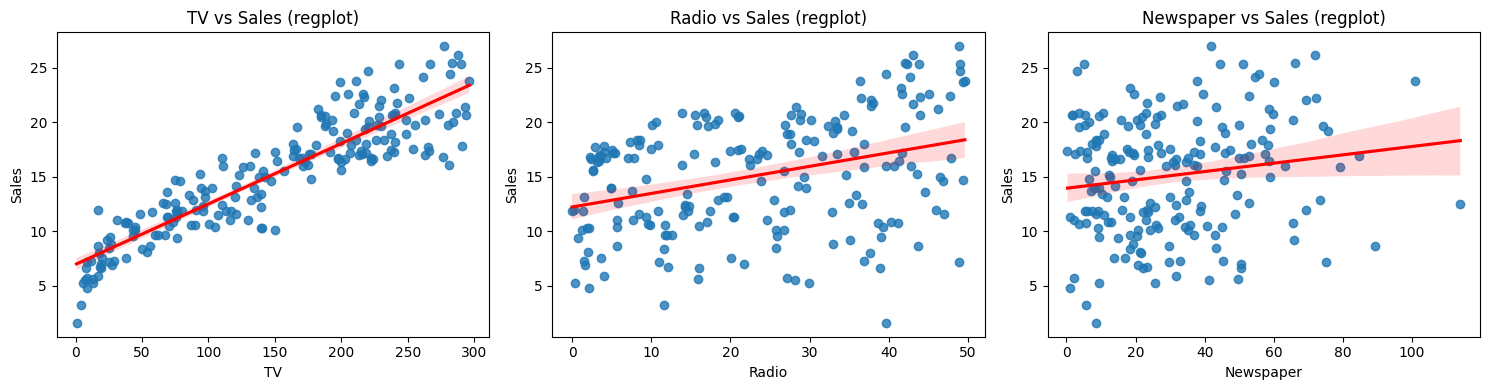

In [32]:
predictores = ['TV', 'Radio', 'Newspaper']

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, variable in zip(ejes, predictores):
    sns.regplot(x=variable, y="Sales", data=df, ax=eje, line_kws={"color": "red"})
    eje.set_title(f"{variable} vs Sales (regplot)")
plt.tight_layout()
plt.show()


**Respuesta:** TV tiene una relación lineal clara y positiva con Sales: los puntos siguen la recta casi sin abrirse. Radio también tiene tendencia positiva, pero los puntos están mucho más dispersos, o sea que la relación es más débil. Newspaper casi no muestra relación: la recta es casi plana y los puntos están regados por todos lados.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

              TV  Radio  Newspaper  Sales
TV         1.000  0.055      0.057  0.901
Radio      0.055  1.000      0.354  0.350
Newspaper  0.057  0.354      1.000  0.158
Sales      0.901  0.350      0.158  1.000


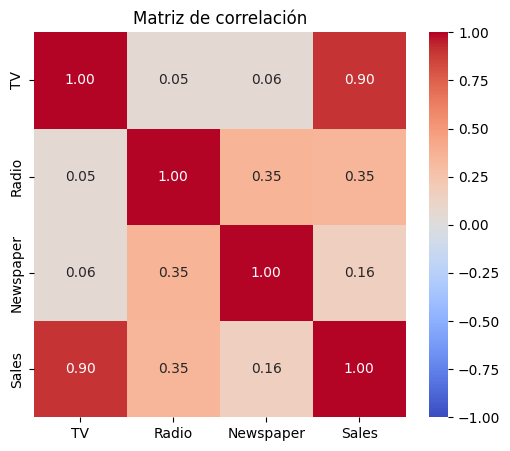

In [33]:
matriz_corr = df.corr()
print(matriz_corr.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()


**Respuesta:** Con Sales la más correlacionada es TV (0.90), luego Radio (0.35) y al final Newspaper (0.16). Entre los predictores no hay correlación alta: la más grande es Radio con Newspaper (0.35), y TV casi no se relaciona con las otras dos (0.06), así que no se ve un problema de predictores repetidos.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

    variable    VIF
0         TV  1.005
1      Radio  1.145
2  Newspaper  1.145


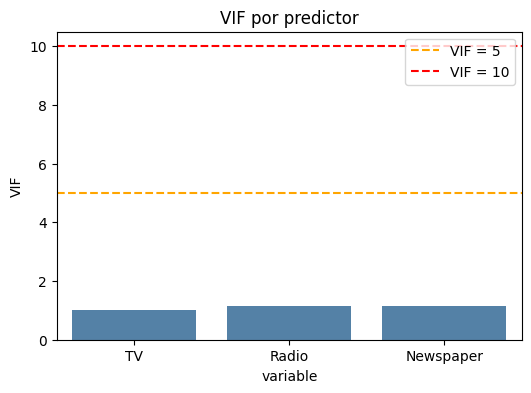

In [34]:
#Multicolinealidad
X_vif = sm.add_constant(df[predictores])

tabla_vif = pd.DataFrame({
    "variable": predictores,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(predictores))]
})
print(tabla_vif.round(3))

plt.figure(figsize=(6, 4))
sns.barplot(x="variable", y="VIF", data=tabla_vif, color="steelblue")
plt.axhline(5, color="orange", linestyle="--", label="VIF = 5")
plt.axhline(10, color="red", linestyle="--", label="VIF = 10")
plt.title("VIF por predictor")
plt.legend()
plt.show()

**Respuesta:** Los VIF son TV 1.005, Radio 1.145 y Newspaper 1.145. Ninguno pasa de 5 ni de 10; todos están muy cerca de 1, que es lo mínimo. Entonces no hay multicolinealidad, y los coeficientes del modelo no se ven afectados por que los predictores se parezcan entre sí. Con esto no hay que quitar ninguna variable por este criterio.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [35]:
#Entrenamiento del Modelo (Todas las Variables Independientes)
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

modelo = LinearRegression()
modelo.fit(X, y)

print("Intercepto:", round(modelo.intercept_, 4))
for variable, coef in zip(X.columns, modelo.coef_):
    print(f"Coeficiente de {variable}: {coef:.4f}")


Intercepto: 4.6251
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


**Respuesta:** El modelo queda Sales = 4.6251 + 0.0544·TV + 0.1070·Radio + 0.0003·Newspaper (unidades del dataset).
- **Intercepto (4.63):** ventas esperadas si no se invierte nada en ningún medio.
- **TV (0.0544):** por cada unidad más de inversión en TV, las ventas suben 0.054 unidades, dejando fijos Radio y Newspaper.
- **Radio (0.1070):** por cada unidad más en Radio, las ventas suben 0.107 unidades, con TV y Newspaper fijos. Por unidad invertida rinde como el doble que TV.
- **Newspaper (0.0003):** casi cero, o sea que un aumento en periódico prácticamente no mueve las ventas.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

Text(0, 0.5, 'Frecuencia')

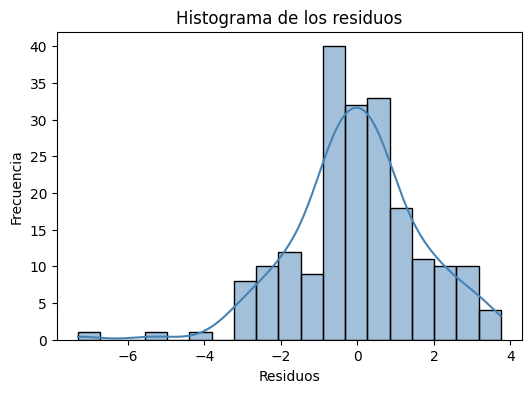

In [36]:
#Normalidad de los residuos
y_pred = modelo.predict(X)
residuos = y - y_pred

plt.figure(figsize=(6, 4))
sns.histplot(residuos, kde=True, color="steelblue")
plt.title("Histograma de los residuos")
plt.xlabel("Residuos")
plt.ylabel("Frecuencia")

**Respuesta:** El histograma tiene forma de campana y está centrado en cero, pero tiene una cola larga hacia la izquierda (unos pocos residuos muy negativos, hasta cerca de −7). Se parece a una normal sin serlo del todo, el sesgo es de −0.43. La prueba de Shapiro-Wilk también rechaza la normalidad (p = 0.0016), aunque a simple vista es una desviación moderada.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

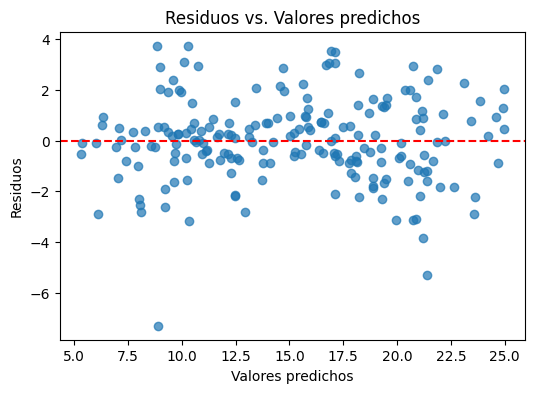

In [37]:
# Homocedasticidad
plt.figure(figsize=(6, 4))
plt.scatter(y_pred, residuos, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos vs. Valores predichos")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.show()

**Respuesta:** Los residuos se reparten alrededor del cero sin formar un abanico, así que la dispersión es más o menos constante (hay homocedasticidad). Se nota una ligera curva, positivos en los extremos (predichos chicos y grandes) y más negativos en medio, y dos residuos muy negativos (cerca de −7 y −5). Es leve y no cambia la conclusión, pero sugiere que la relación no es perfectamente lineal.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

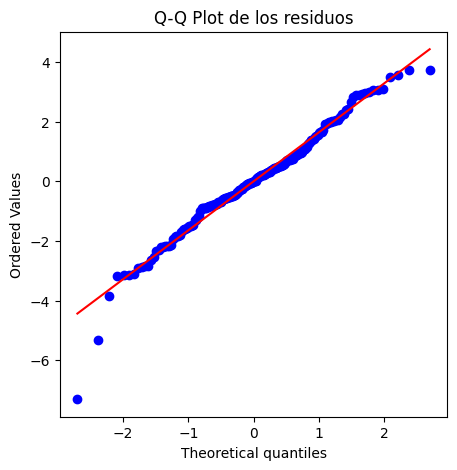

In [38]:
#Q-Q Plot
plt.figure(figsize=(5, 5))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos")
plt.show()

**Respuesta:** Casi todos los puntos caen sobre la diagonal, así que en general los residuos siguen una normal. Los puntos de la cola izquierda se salen hacia abajo (los dos residuos muy negativos), lo que indica una cola pesada del lado de los errores negativos. Esto coincide con el sesgo y con lo que se vio en el histograma.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [39]:
#Evaluación del Modelo
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.4f}")

MSE: 2.706
RMSE: 1.645
R²: 0.9026


**Respuesta:** MSE = 2.706, RMSE = 1.645 y R² = 0.9026. El R² dice que el modelo explica cerca del 90% de la variación de las ventas. El RMSE dice que, en promedio, las predicciones se equivocan por unos 1.65 (en las unidades de Sales), lo cual es poco frente al rango de Sales (de 1.6 a 27). Es un buen ajuste.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

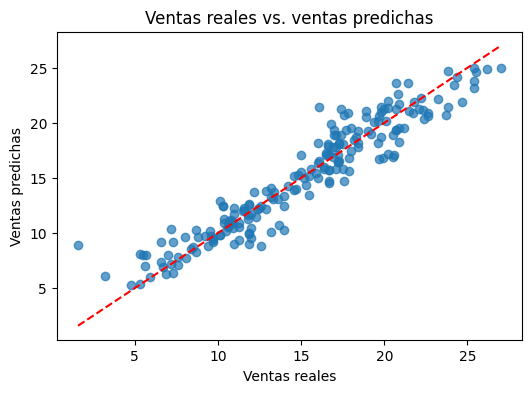

In [40]:
#Visualización de las Predicciones
plt.figure(figsize=(6, 4))
plt.scatter(y, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
plt.title("Ventas reales vs. ventas predichas")
plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.show()

**Respuesta:** Los puntos siguen bastante la diagonal (predicción perfecta), o sea que las predicciones son cercanas a lo real. Se ve algo más de error en los extremos: ventas muy bajas (el punto cerca de 1.6, que el modelo predice en 9) y algunas ventas altas que se subestiman. Sirve para ver de un vistazo dónde falla el modelo.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [41]:
#P-values
X = sm.add_constant(X)
modelo_stats = sm.OLS(y, X).fit()
print(modelo_stats.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        04:54:16   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Respuesta:** TV (p = 0.000) y Radio (p = 0.000) tienen p-value menor a 0.05, y Newspaper tiene p = 0.954, muy por arriba. Conclusión: TV y Radio sí tienen un efecto significativo sobre las ventas; Newspaper no, su coeficiente (0.0003) no se distingue de cero (su intervalo de confianza va de −0.011 a 0.012), así que no aporta al modelo cuando ya están TV y Radio.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [42]:
# Parte 5: ¿hay variables con multicolinealidad (VIF > 5)?
con_vif_alto = tabla_vif[tabla_vif["VIF"] > 5]
print("Variables con VIF > 5:", list(con_vif_alto["variable"]))
print("VIF máximo:", round(tabla_vif["VIF"].max(), 3))

Variables con VIF > 5: []
VIF máximo: 1.145


**Respuesta:** Como el VIF de las tres variables es menor a 5 (el máximo es 1.145), no hay variables con multicolinealidad que eliminar. Por eso no se construye un modelo nuevo: quedaría con las mismas variables que el de la Parte 4 y daría exactamente los mismos resultados (R² = 0.9026, RMSE = 1.645). Para la comparación final, este modelo es el mismo de la Parte 4.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [43]:
# Entrenamiento del modelo (Sin Newspaper)
X6 = df[["TV", "Radio"]]

modelo6 = LinearRegression()
modelo6.fit(X6, y)

print("Intercepto:", round(modelo6.intercept_, 4))
for variable, coef in zip(X6.columns, modelo6.coef_):
    print(f"Coeficiente de {variable}: {coef:.4f}")

Intercepto: 4.6309
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1072


**Respuesta:** Se quitó Newspaper porque es la que no tiene relación lineal con Sales (correlación de 0.16, recta casi plana en la dispersión y p = 0.954 en el modelo). El modelo queda Sales = 4.6309 + 0.0544·TV + 0.1072·Radio. Los coeficientes de TV y Radio casi no cambiaron respecto a la Parte 4, lo que confirma que Newspaper no aportaba.

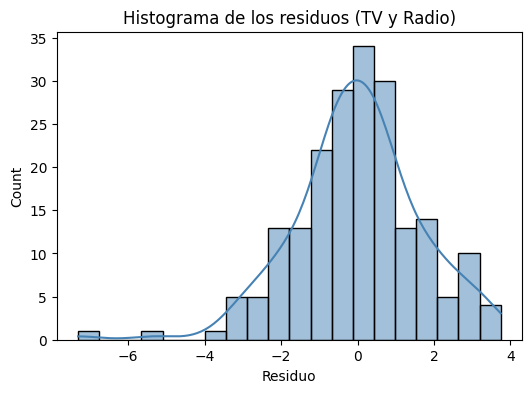

In [44]:
#Normalidad de los residuos
y_pred6 = modelo6.predict(X6)
residuos6 = y - y_pred6

plt.figure(figsize=(6, 4))
sns.histplot(residuos6, kde=True, bins=20, color="steelblue")
plt.title("Histograma de los residuos (TV y Radio)")
plt.xlabel("Residuo")
plt.show()

**Respuesta:** Es prácticamente igual que en la Parte 4: forma de campana centrada en cero con una cola larga a la izquierda. No se distribuyen perfectamente normales (Shapiro-Wilk p ≈ 0.0015), pero la desviación es moderada.

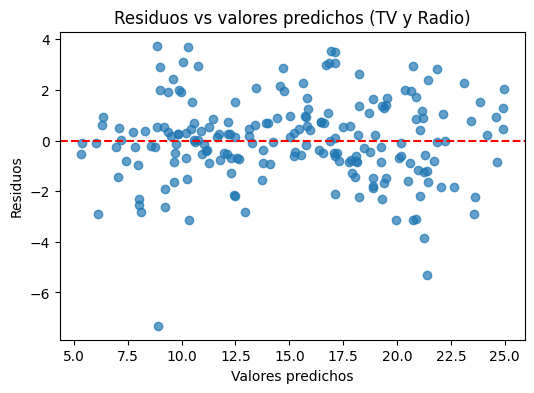

In [45]:
plt.figure(figsize=(6, 4))
plt.scatter(y_pred6, residuos6, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos vs valores predichos (TV y Radio)")
plt.show()

**Respuesta:** Mismo comportamiento que antes: los residuos se reparten alrededor de cero con dispersión más o menos constante, con una ligera curva y un par de residuos muy negativos. Quitar Newspaper no cambió esto.

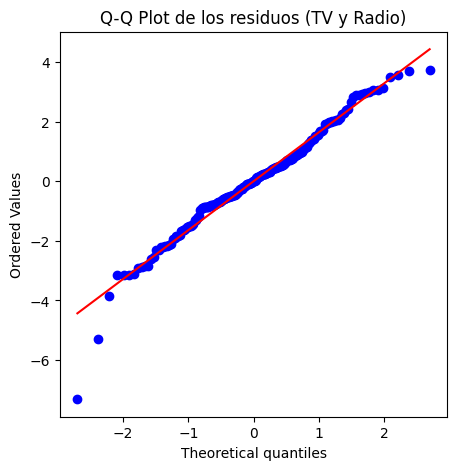

In [46]:
# Q-Q Plot
plt.figure(figsize=(5, 5))
stats.probplot(residuos6, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos (TV y Radio)")
plt.show()

**Respuesta:** La mayoría de los puntos queda sobre la diagonal y se desvían los de la cola izquierda, igual que en la Parte 4. Los residuos son aproximadamente normales, con cola pesada del lado negativo.

In [47]:
# Evaluacion del modelo
mse6 = mean_squared_error(y, y_pred6)
rmse6 = np.sqrt(mse6)
r2_6 = r2_score(y, y_pred6)

print(f"MSE: {mse6:.3f}")
print(f"RMSE: {rmse6:.3f}")
print(f"R²: {r2_6:.4f}")

MSE: 2.706
RMSE: 1.645
R²: 0.9026


**Respuesta:** MSE = 2.706, RMSE = 1.645 y R² = 0.9026, los mismos valores que con las tres variables. Quitar Newspaper no hizo perder nada de ajuste, y el R² ajustado incluso subió un poco (0.9016 contra 0.9011), porque el modelo es más simple.

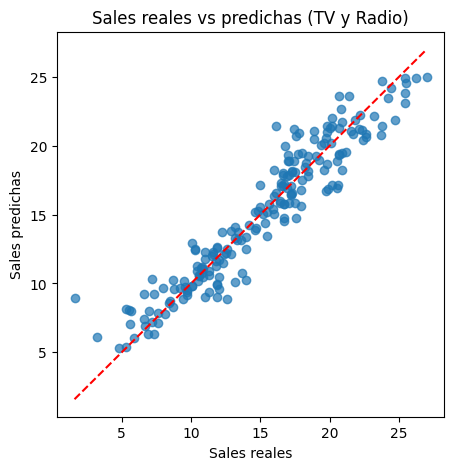

In [48]:
# Visualizaciones de predicciones
plt.figure(figsize=(5, 5))
plt.scatter(y, y_pred6, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", linestyle="--")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.title("Sales reales vs predichas (TV y Radio)")
plt.show()

**Respuesta:** La gráfica es prácticamente idéntica a la de la Parte 4: puntos cerca de la diagonal, con más error en los extremos. Se predice igual de bien con dos variables que con tres.

In [49]:
#Impacto de los atributos (P-Values)
X6_sm = sm.add_constant(X6)
modelo6_sm = sm.OLS(y, X6_sm).fit()
print(modelo6_sm.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        04:54:17   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

**Respuesta:** TV (p = 0.000) y Radio (p = 0.000) son significativas, ambas con p-value menor a 0.05. Sus coeficientes (0.0544 y 0.1072) son prácticamente los mismos que con tres variables, y los errores estándar siguen igual de pequeños. Con eso se confirma que el modelo de TV y Radio es suficiente.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

In [50]:

# Comparación de los modelos
comparacion = pd.DataFrame({
    "modelo": ["Parte 4: TV + Radio + Newspaper", "Parte 6: TV + Radio"],
    "R2": [r2, r2_6],
    "R2_ajustado": [modelo_stats.rsquared_adj, modelo6_sm.rsquared_adj],
    "RMSE": [rmse, rmse6],
})
display(comparacion.round(4))

# R2 de cada predictor por separado, para ver cuánto explica cada uno
for variable in predictores:
    r2_solo = LinearRegression().fit(df[[variable]], y).score(df[[variable]], y)
    print(f"R² usando solo {variable}: {r2_solo:.4f}")


,modelo,R2,R2_ajustado,RMSE
0,Parte 4: TV + Radio + Newspaper,0.9026,0.9011,1.645
1,Parte 6: TV + Radio,0.9026,0.9016,1.645


R² usando solo TV: 0.8122
R² usando solo Radio: 0.1222
R² usando solo Newspaper: 0.0250


**Respuesta (Conclusiones):**
- **Mejor modelo:** el de la Parte 6 (TV + Radio). Tiene el mismo R² (0.9026) y el mismo RMSE (1.645) que el modelo completo, un R² ajustado un poco mayor (0.9016 contra 0.9011) y usa una variable menos, porque Newspaper no es significativa (p = 0.954). El modelo de la Parte 5 es el mismo que el de la Parte 4, ya que no había multicolinealidad (VIF máximo de 1.145), así que en la práctica hay dos modelos distintos y gana el más simple.
- **Atributo con más influencia:** TV. Es la que más se relaciona con las ventas (correlación de 0.90), la de mayor estadístico t (39.7) y, usada sola, explica el 81% de la variación de Sales (R² = 0.8122), contra 12% de Radio y 2.5% de Newspaper. Ojo: por cada unidad invertida, Radio tiene un coeficiente mayor (0.107 contra 0.054), pero TV es la que más aporta a explicar las ventas en total.